In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy
import mlxtend

In [64]:
df = pd.read_csv("data/ecology/environmental_monthly.csv")

## Vérification de la qualité des données

In [65]:
df.head()
print("Dimensions :", df.shape)
print("\nTypes des colonnes :")
print(df.dtypes)
display(df.head())
display(df.sample(min(5, len(df)), random_state=42))

Dimensions : (4994, 11)

Types des colonnes :
site_code                        str
reporting_month                  str
mean_temperature_c               str
rainfall_mm                      str
mean_humidity_pct                str
vegetation_cover_pct         float64
habitat_disturbance_index    float64
pesticide_index              float64
land_use_category                str
weather_exception_code           str
data_completeness_pct        float64
dtype: object


,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,land_use_category,weather_exception_code,data_completeness_pct
0,KNT-KES,2019-01-01,25.25,95.0,74.4,69.7,25.9,31.6,karst_habitat,NaN,98.6
1,KNT-KES,2019-02-01,25.72,78.5,67.3,64.1,23.5,19.4,karst_habitat,NaN,90.4
2,KNT-KES,2019-03-01,25.8,100.4,67.0,62.8,24.6,18.0,karst_habitat,NaN,100.0
3,KNT-KES,2019-04-01,26.68,189.2,68.8,68.5,19.0,21.7,karst_habitat,NaN,96.0
4,KNT-KES,2019-05-01,26.87,198.9,75.9,74.3,21.1,17.1,karst_habitat,NaN,93.9


,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,land_use_category,weather_exception_code,data_completeness_pct
84,KNT-LUM,2019-07-01,26.63,261.2,83.7,64.9,57.3,13.9,karst_habitat,NaN,98.0
1144,KNT-VLB,2023-05-01,25.78,224.0,84.2,75.8,10.8,27.3,mixed_forest,NaN,99.8
2949,AVL-YAU,2024-04-01,27.83,81.0,68.0,64.1,28.4,37.3,durian_orchard,NaN,96.4
653,KNT-CYP,2021-06-01,26.92,186.0,84.6,66.2,12.1,0.0,karst_habitat,NaN,100.0
2290,AVL-ARU,2021-05-01,27.4,72.0,76.2,46.4,45.7,14.2,research_site,NaN,94.7


Valeurs manquantes et doublons

In [66]:
display(pd.DataFrame({
    "valeurs_manquantes": df.isna().sum(),
    "pourcentage": (df.isna().mean() * 100).round(2)
}))
print("Doublons exacts :", df.duplicated().sum())

,valeurs_manquantes,pourcentage
site_code,0,0.00
reporting_month,0,0.00
mean_temperature_c,0,0.00
rainfall_mm,0,0.00
mean_humidity_pct,0,0.00
vegetation_cover_pct,10,0.20
habitat_disturbance_index,0,0.00
pesticide_index,15,0.30
land_use_category,0,0.00
weather_exception_code,4790,95.92


Doublons exacts : 2


Formats et catégories

In [67]:
colonnes_categorielles = ['weather_exception_code', 'land_use_category', 'site_code']
for col in colonnes_categorielles:
    print(f"\n{col} :")
    print(df[col].value_counts(dropna=False).head(25))


weather_exception_code :
weather_exception_code
NaN           4790
HEAVY_RAIN     112
DRY_SPELL       92
Name: count, dtype: int64

land_use_category :
land_use_category
mixed_forest         1481
coastal_habitat       780
durian_orchard        779
karst_habitat         697
research_site         467
mixed_agriculture     388
protected_forest      234
degraded_land         153
Karst_Habitat           4
DEGRADED_LAND           2
DURIAN_ORCHARD          2
Degraded_Land           1
KARST_HABITAT           1
Research_Site           1
Durian_Orchard          1
MIXED_AGRICULTURE       1
Mixed_Agriculture       1
Mixed_Forest            1
Name: count, dtype: int64

site_code :
site_code
AVL-NMQ    80
KNT-KES    78
KNT-LUM    78
KNT-SEN    78
AVL-MAR    78
AVL-VEL    78
AVL-ORR    78
TMB-NAC    78
TMB-PEL    78
KNT-CYP    78
KNT-YRX    78
KNT-GKR    78
KNT-NNM    78
KNT-JAK    78
KNT-JQG    78
KNT-VLB    78
KNT-CHP    78
KNT-YRG    78
KNT-WUQ    78
KNT-DMJ    78
KNT-GGN    78
KNT-QWU    78
KNT-

Vérification des valeurs présentes dans les colonnes numériques

In [68]:
for col in ["mean_temperature_c", "rainfall_mm", "mean_humidity_pct", "vegetation_cover_pct", "habitat_disturbance_index", "pesticide_index", "data_completeness_pct"]:
    print(col, "→", df[col].unique()[:30])

mean_temperature_c → <StringArray>
['25.25', '25.72',  '25.8', '26.68', '26.87', '25.24', '24.56', '23.96',
 '23.93', '24.09', '24.87', '24.78', '25.96', '26.96', '27.51', '28.25',
 '26.48', '25.89', '23,81', '23.85', '23.77', '23.68', '25.57', '25.86',
 '26.58', '26.75', '26.67', '26.57', '25.02', '24.18']
Length: 30, dtype: str
rainfall_mm → <StringArray>
[ '95.0',  '78.5', '100.4', '189.2', '198.9', '169.0', '272.9', '239.8',
 '224.5', '153.6',  '94.4',  '49.7',  '44.8', '114.2', '142.6', '157.1',
 '222.0', '219.5', '255.5', '272.2', '211.1', '177.7', '130.2',  '39.3',
  '73.4',  '48.5', '111.2', '133.2', '209.6', '157.9']
Length: 30, dtype: str
mean_humidity_pct → <StringArray>
['74.4', '67.3', '67.0', '68.8', '75.9', '77.0', '80.8', '81.1', '80.9',
 '73.3', '75.8', '69.7', '64.5', '71.2', '76.9', '82.5', '84.4', '84.2',
 '83.6', '86.6', '74,8', '76.3', '71.6', '71.1', '64,7', '71.3', '72.2',
 '83.5', '85.0', '84.3']
Length: 30, dtype: str
vegetation_cover_pct → [69.7 64.1 62.8 68.

Identification des valeurs non numériques dans les colonnes

In [69]:
colonnes_numeriques = [
    'mean_temperature_c',
    'rainfall_mm',
    'mean_humidity_pct',
    'vegetation_cover_pct',
    'habitat_disturbance_index',
    'pesticide_index',
    'data_completeness_pct'
]

In [70]:
for col in colonnes_numeriques:
    mask = pd.to_numeric(df[col], errors="coerce").isna() & df[col].notna()
    if mask.any():
        print(f"{col} → valeurs problématiques :", df.loc[mask, col].unique())

mean_temperature_c → valeurs problématiques : <StringArray>
[  '23,81',   '26,34',   '29,35',   '26,63',   '24,65',   '26,56', '25.86 C',
  '23.3 C',   '24,21', '23.73 C',   '21,92', '24.47 C',   '25,76',   '27,72',
 '22.95 C', '26.81 C', '24.73 C',   '28,61', '28.07 C',   '28,54',   '27,78',
   '27,19', '29.22 C',  '28.2 C',   '28,72', '25.82 C',   '27,66',   '28,88',
 '26.66 C',   '26,55',   '28,42',   '27,33', '27.04 C', '28.54 C',   '25,91',
 '23.91 C',   '27,15',   '26,05',   '27,01',   '27,76']
Length: 40, dtype: str
rainfall_mm → valeurs problématiques : <StringArray>
['102.7 mm',     '75,5', '251.3 mm',  '67.9 mm',  '29.5 mm',  '91.9 mm',
 '210.9 mm', '216.7 mm',    '220,6',    '196,1', '186.5 mm', '282.5 mm',
 '178.1 mm',    '140,3',    '197,5',     '17,3', '143.7 mm',    '275,7',
 '229.6 mm', '213.1 mm',  '77.2 mm',     '63,4',    '107,0',    '201,4',
     '87,5', '166.3 mm',  '96.1 mm', '287.0 mm', '123.9 mm',    '247,2',
    '284,7', '238.1 mm',    '200,9',    '200,2',     

## Nettoyage des données

suppression des doublons exacts

In [71]:
df_clean = df.copy()
# Suppression des lignes strictement identiques.
df_clean = df_clean.drop_duplicates().copy()
print("Dimensions après suppression des doublons exacts :", df_clean.shape)

Dimensions après suppression des doublons exacts : (4992, 11)


 Uniformiser les catégories

In [72]:
for col in colonnes_categorielles:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

Uniformiser les colonnes numériques

In [73]:
for col in colonnes_numeriques:
    valeurs = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    # Supprimer les unités connues
    if col == 'mean_temperature_c':
        valeurs = valeurs.str.replace(
            r'\s*°?\s*C\s*$', '', regex=True, case=False
        )

    if col == 'rainfall_mm':
        valeurs = valeurs.str.replace(
            r'\s*mm\s*$', '', regex=True, case=False
        )

    # Conversion numérique
    nombres = pd.to_numeric(valeurs, errors="coerce")

    # Identifier les valeurs qui restent non convertibles
    erreurs = valeurs.notna() & nombres.isna()

    if erreurs.any():
        print(
            f"Valeurs non numériques dans {col} :",
            valeurs[erreurs].unique().tolist()[:15]
        )

    df_clean[col] = nombres

display(df_clean.head())

,site_code,reporting_month,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,land_use_category,weather_exception_code,data_completeness_pct
0,knt-kes,2019-01-01,25.25,95.0,74.4,69.7,25.9,31.6,karst_habitat,<NA>,98.6
1,knt-kes,2019-02-01,25.72,78.5,67.3,64.1,23.5,19.4,karst_habitat,<NA>,90.4
2,knt-kes,2019-03-01,25.8,100.4,67.0,62.8,24.6,18.0,karst_habitat,<NA>,100.0
3,knt-kes,2019-04-01,26.68,189.2,68.8,68.5,19.0,21.7,karst_habitat,<NA>,96.0
4,knt-kes,2019-05-01,26.87,198.9,75.9,74.3,21.1,17.1,karst_habitat,<NA>,93.9


Convertir les dates dans un format cohérent.

In [74]:
print("Dates manquantes :",
      df_clean['reporting_month'].isna().sum())

Dates manquantes : 0


In [75]:
# Convertir uniquement si la colonne n'est pas déjà au format datetime
if not pd.api.types.is_datetime64_any_dtype(df_clean['reporting_month']):
    df_clean['reporting_month'] = pd.to_datetime(
        df_clean['reporting_month'],
        errors='coerce'
    )

print("Dates manquantes :",
      df_clean['reporting_month'].isna().sum())

Dates manquantes : 0


## Vérifications 

Analyser les valeurs manquantes

In [76]:
missing = pd.DataFrame({
    "nb_manquantes": df_clean.isna().sum(),
    "pourcentage": (df_clean.isna().mean() * 100).round(2)
})

display(missing[missing["nb_manquantes"] > 0])

,nb_manquantes,pourcentage
vegetation_cover_pct,10,0.20
pesticide_index,15,0.30
weather_exception_code,4788,95.91


Vérification 

In [77]:
# Vérifier les catégories
for col in colonnes_categorielles:
    print(f"\n{col}")
    print(df_clean[col].value_counts(dropna=False))

# Vérifier les types
print("\nTypes des colonnes nettoyées :")
print(df_clean[colonnes_numeriques].dtypes)
# Vérifier les valeurs manquantes
print("\nValeurs manquantes :")
print(df_clean[colonnes_numeriques].isna().sum())


weather_exception_code
weather_exception_code
<NA>          4788
heavy_rain     112
dry_spell       92
Name: count, dtype: Int64

land_use_category
land_use_category
mixed_forest         1482
durian_orchard        780
coastal_habitat       780
karst_habitat         702
research_site         468
mixed_agriculture     390
protected_forest      234
degraded_land         156
Name: count, dtype: Int64

site_code
site_code
knt-kes    78
knt-lum    78
knt-sen    78
avl-mar    78
avl-vel    78
           ..
tmb-wst    78
tmb-sxp    78
tmb-wql    78
tmb-qcb    78
tmb-dlq    78
Name: count, Length: 64, dtype: Int64

Types des colonnes nettoyées :
mean_temperature_c           Float64
rainfall_mm                  Float64
mean_humidity_pct            Float64
vegetation_cover_pct         Float64
habitat_disturbance_index    Float64
pesticide_index              Float64
data_completeness_pct        Float64
dtype: object

Valeurs manquantes :
mean_temperature_c            0
rainfall_mm                

Vérifier les valeurs impossibles

In [78]:
# Colonnes devant être positives ou nulles
colonnes_positives = [
    'rainfall_mm',
    'habitat_disturbance_index',
    'pesticide_index'
]

for col in colonnes_positives:
    invalides = df_clean[col].notna() & (df_clean[col] < 0)

    print(f"{col} : {invalides.sum()} valeurs négatives")

    if invalides.any():
        display(df_clean.loc[invalides, ['site_code', col]])


# Colonnes exprimées en pourcentage
colonnes_pct = [
    'mean_humidity_pct',
    'vegetation_cover_pct',
    'data_completeness_pct'
]

for col in colonnes_pct:
    invalides = (
        df_clean[col].notna()
        & ~df_clean[col].between(0, 100)
    )

    print(f"{col} : {invalides.sum()} valeurs hors [0, 100]")

    if invalides.any():
        display(df_clean.loc[invalides, ['site_code', col]])

rainfall_mm : 0 valeurs négatives
habitat_disturbance_index : 0 valeurs négatives
pesticide_index : 0 valeurs négatives
mean_humidity_pct : 0 valeurs hors [0, 100]
vegetation_cover_pct : 0 valeurs hors [0, 100]
data_completeness_pct : 0 valeurs hors [0, 100]


Vérifier l'unicité des mesures mensuelles

In [79]:
doublons = df_clean.duplicated(
    subset=['site_code', 'reporting_month'],
    keep=False
)

print(
    "Lignes avec site/mois dupliqué :",
    doublons.sum()
)

if doublons.any():
    display(
        df_clean.loc[doublons]
        .sort_values(['site_code', 'reporting_month'])
    )

Lignes avec site/mois dupliqué : 0


Vérifier les dates manquantes

In [80]:
print(
    "Dates manquantes ou invalides :",
    df_clean['reporting_month'].isna().sum()
)

print(
    "Sites manquants :",
    df_clean['site_code'].isna().sum()
)

Dates manquantes ou invalides : 0
Sites manquants : 0


## Statistiques descriptives

In [81]:
colonnes_numeriques = ['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct', 'vegetation_cover_pct', 'habitat_disturbance_index', 'pesticide_index', 'data_completeness_pct']
display(df_clean[colonnes_numeriques].describe().T)

for col in ['land_use_category', 'weather_exception_code', 'site_code']:
    print(f"\nRépartition de {col} :")
    display(df_clean[col].value_counts(dropna=False).head(20).to_frame("effectif"))

,count,mean,std,min,25%,50%,75%,max
mean_temperature_c,4992.0,26.377073,1.672062,21.3,25.19,26.35,27.6125,32.0
rainfall_mm,4992.0,159.89403,74.901939,5.0,95.7,156.25,221.7,384.3
mean_humidity_pct,4992.0,75.841847,7.248342,56.7,70.3,75.9,81.5,96.4
vegetation_cover_pct,4982.0,61.014211,13.997015,15.0,52.7,62.3,70.9,98.0
habitat_disturbance_index,4992.0,30.364423,16.358109,0.0,17.9,29.4,41.4,86.8
pesticide_index,4977.0,25.016395,16.26636,0.0,11.6,25.2,37.5,77.3
data_completeness_pct,4992.0,95.961819,2.817944,85.5,94.0,96.15,98.2,100.0



Répartition de land_use_category :


,effectif
land_use_category,
mixed_forest,1482
durian_orchard,780
coastal_habitat,780
karst_habitat,702
research_site,468
mixed_agriculture,390
protected_forest,234
degraded_land,156



Répartition de weather_exception_code :


,effectif
weather_exception_code,
<NA>,4788
heavy_rain,112
dry_spell,92



Répartition de site_code :


,effectif
site_code,
knt-kes,78
knt-lum,78
knt-sen,78
avl-mar,78
avl-vel,78
avl-orr,78
tmb-nac,78
tmb-pel,78
knt-cyp,78


histogramme et une boîte à moustaches

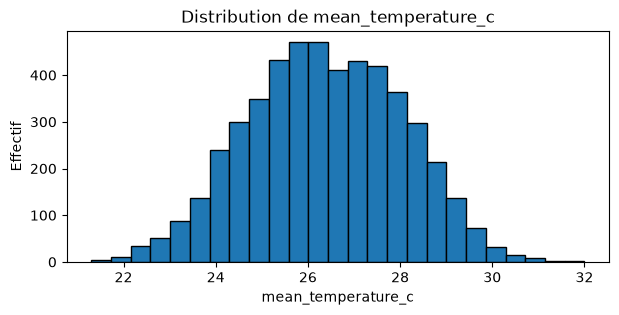

C:\Users\Admin\AppData\Local\Temp\ipykernel_14948\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


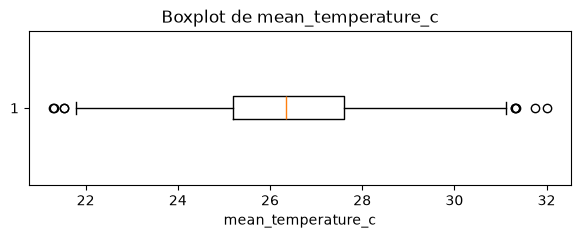

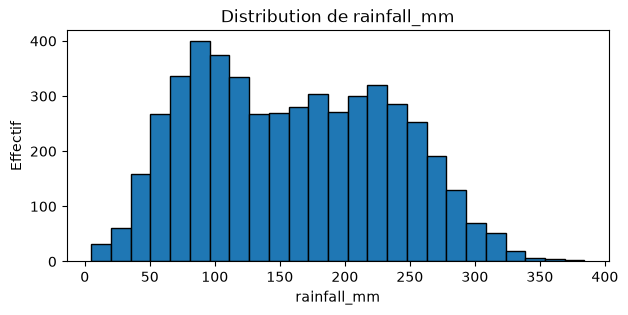

C:\Users\Admin\AppData\Local\Temp\ipykernel_14948\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


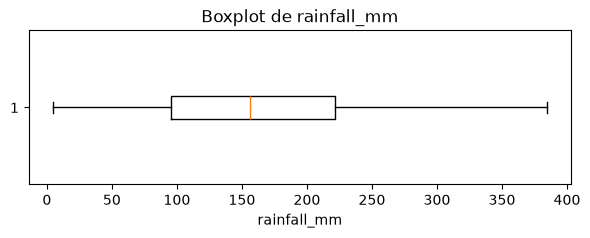

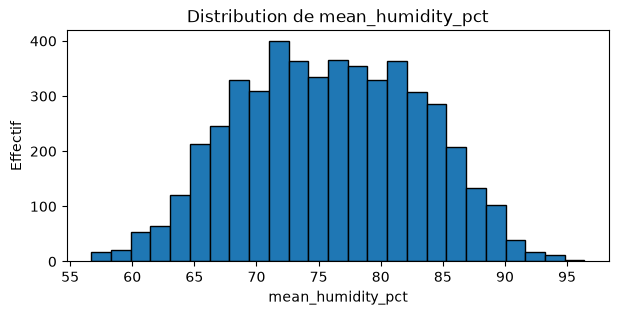

C:\Users\Admin\AppData\Local\Temp\ipykernel_14948\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


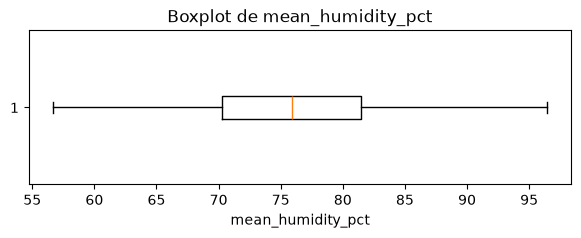

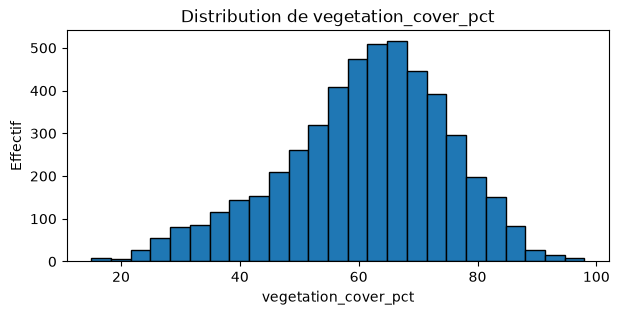

C:\Users\Admin\AppData\Local\Temp\ipykernel_14948\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


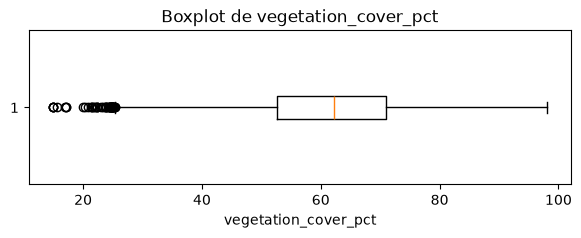

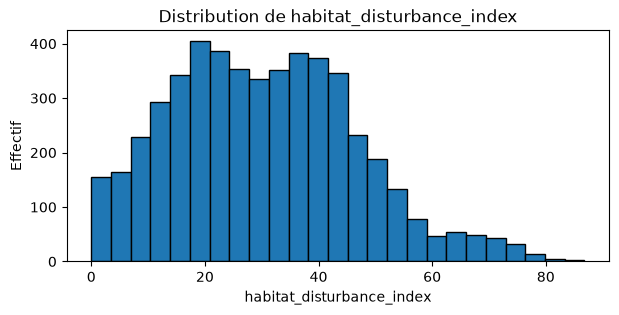

C:\Users\Admin\AppData\Local\Temp\ipykernel_14948\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


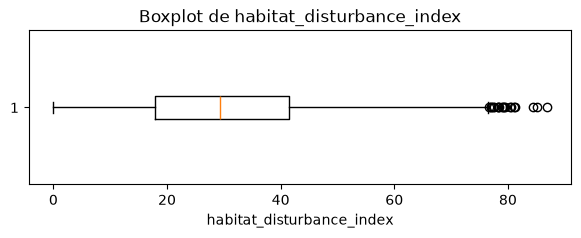

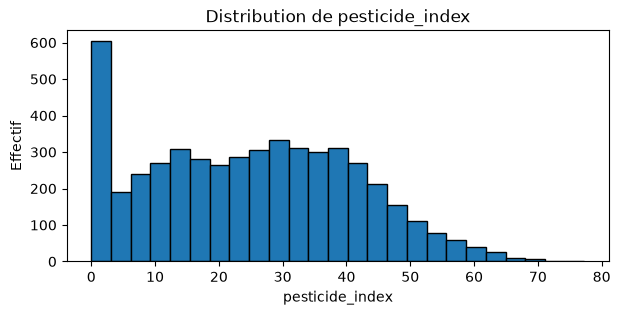

C:\Users\Admin\AppData\Local\Temp\ipykernel_14948\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


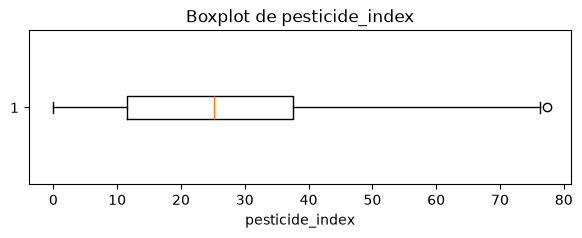

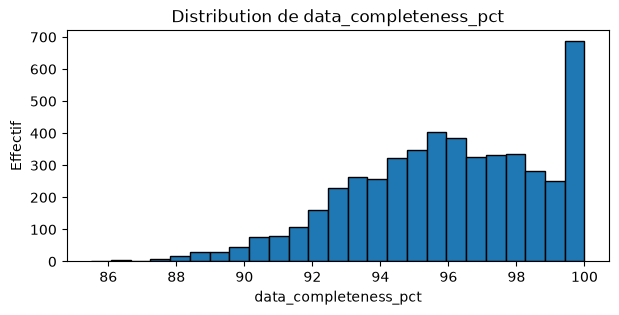

C:\Users\Admin\AppData\Local\Temp\ipykernel_14948\983984861.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valeurs, vert=False)


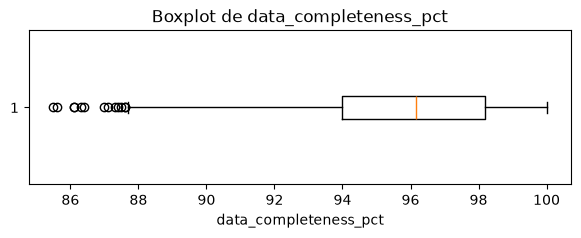

In [82]:
for col in colonnes_numeriques:
    valeurs = df_clean[col].dropna()
    if valeurs.empty:
        continue
    plt.figure(figsize=(7, 3))
    plt.hist(valeurs, bins=25, edgecolor="black")
    plt.title(f"Distribution de {col}")
    plt.xlabel(col)
    plt.ylabel("Effectif")
    plt.show()

    plt.figure(figsize=(7, 2))
    plt.boxplot(valeurs, vert=False)
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)
    plt.show()

Comparer les variables

,mean_temperature_c,rainfall_mm,mean_humidity_pct,vegetation_cover_pct,habitat_disturbance_index,pesticide_index,data_completeness_pct
mean_temperature_c,1.00,-0.21,-0.26,-0.05,0.00,-0.09,0.00
rainfall_mm,-0.21,1.00,0.73,0.32,0.02,0.08,-0.00
mean_humidity_pct,-0.26,0.73,1.00,0.24,0.03,-0.01,-0.01
vegetation_cover_pct,-0.05,0.32,0.24,1.00,-0.38,-0.04,0.02
habitat_disturbance_index,0.00,0.02,0.03,-0.38,1.00,0.04,0.00
pesticide_index,-0.09,0.08,-0.01,-0.04,0.04,1.00,0.00
data_completeness_pct,0.00,-0.00,-0.01,0.02,0.00,0.00,1.00


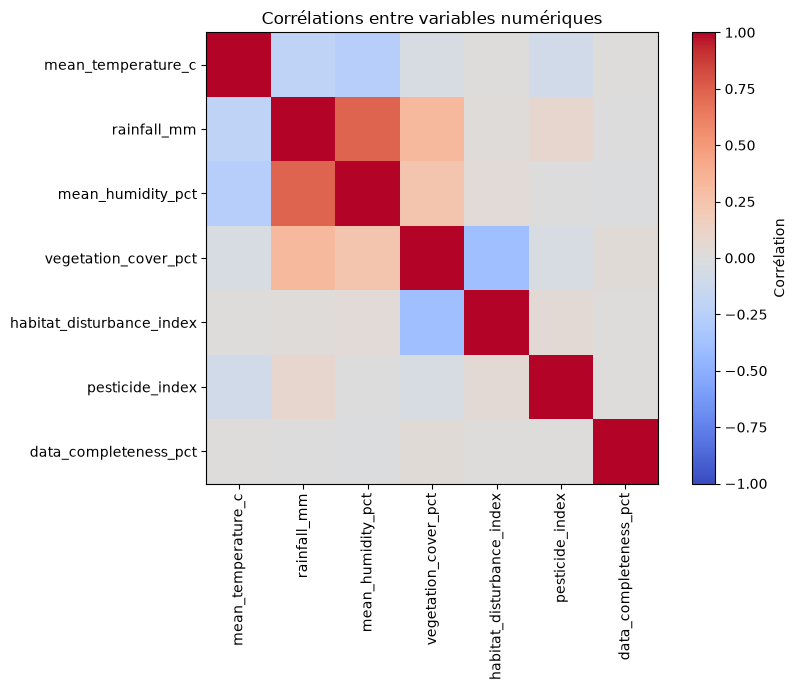

In [83]:
correlations = df_clean[colonnes_numeriques].corr()
display(correlations.round(2))

plt.figure(figsize=(9, 7))
plt.imshow(correlations, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Corrélation")
plt.xticks(range(len(correlations)), correlations.columns, rotation=90)
plt.yticks(range(len(correlations)), correlations.index)
plt.title("Corrélations entre variables numériques")
plt.tight_layout()
plt.show()

Repérer des associations simples

In [84]:
# Tableau croisé entre deux variables catégorielles.
col_a, col_b = 'land_use_category', 'weather_exception_code'
cooccurrences = pd.crosstab(df_clean[col_a], df_clean[col_b])
display(cooccurrences)
# Normalisation par ligne : chaque ligne représente 100 %.
display((pd.crosstab(df_clean[col_a], df_clean[col_b], normalize="index") * 100).round(1))

weather_exception_code,dry_spell,heavy_rain
land_use_category,,
coastal_habitat,8,32
degraded_land,0,3
durian_orchard,15,12
karst_habitat,12,10
mixed_agriculture,3,22
mixed_forest,34,32
protected_forest,7,0
research_site,13,1


weather_exception_code,dry_spell,heavy_rain
land_use_category,,
coastal_habitat,20.0,80.0
degraded_land,0.0,100.0
durian_orchard,55.6,44.4
karst_habitat,54.5,45.5
mixed_agriculture,12.0,88.0
mixed_forest,51.5,48.5
protected_forest,100.0,0.0
research_site,92.9,7.1


## Export des données nettoyées

In [85]:
print("===== BILAN FINAL DU NETTOYAGE =====")

print("Lignes initiales :", len(df))
print("Lignes finales :", len(df_clean))
print("Doublons exacts :", df_clean.duplicated().sum())

print("\nValeurs manquantes restantes :")
display(df_clean.isna().sum().to_frame("Nombre"))

print("\nTypes des colonnes :")
display(df_clean.dtypes.to_frame("Type"))

===== BILAN FINAL DU NETTOYAGE =====
Lignes initiales : 4994
Lignes finales : 4992
Doublons exacts : 0

Valeurs manquantes restantes :


,Nombre
site_code,0
reporting_month,0
mean_temperature_c,0
rainfall_mm,0
mean_humidity_pct,0
vegetation_cover_pct,10
habitat_disturbance_index,0
pesticide_index,15
land_use_category,0
weather_exception_code,4788



Types des colonnes :


,Type
site_code,string
reporting_month,datetime64[us]
mean_temperature_c,Float64
rainfall_mm,Float64
mean_humidity_pct,Float64
vegetation_cover_pct,Float64
habitat_disturbance_index,Float64
pesticide_index,Float64
land_use_category,string
weather_exception_code,string


In [86]:
df_clean.to_csv("environmental_monthly_clean.csv", index=False)
print("Fichier créé : environmental_monthly_clean.csv")

Fichier créé : environmental_monthly_clean.csv
